In [1]:
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker

import xarray as xr

import intake

import sys
sys.path.append("/Users/alessandrostorer/Desktop/PhD/1st_yy/work/codes/COARE3.5/")  ## importing original meteo and coare35nv modules
import coare35vn


# - setting gobal variables once for all
Rd = 287.
g = 9.81     # m/s2
Lv = 2.5e3   # J/g 
cp = 1.004   # J/g

In [5]:
## open data from EUREC4A
allFluxes_eu = xr.open_dataset("/Users/alessandrostorer/Desktop/PhD/1st_yy/work/datasets/actual_fluxes/EUREC4A_Meteor_surface_heat_fluxes_20200115_v1.0.nc")
allFluxes_eu

<xarray.Dataset> Size: 371kB
Dimensions:                      (time: 2016, nbnds: 2)
Coordinates:
  * time                         (time) datetime64[ns] 16kB 2020-01-15 ... 20...
Dimensions without coordinates: nbnds
Data variables: (12/41)
    lat                          (time) float32 8kB ...
    lon                          (time) float32 8kB ...
    time_bnds                    (time, nbnds) datetime64[ns] 32kB ...
    SHF_EC_mast                  (time) float32 8kB ...
    SHF_bulk_mast                (time) float32 8kB ...
    LHF_EC_mast                  (time) float32 8kB ...
    ...                           ...
    mask_despiking_T_mast        (time) float32 8kB ...
    mask_despiking_Z_mast        (time) float32 8kB ...
    mask_data_availability_mast  (time) float32 8kB ...
    mask_vsea_bulk_mast          (time) float32 8kB ...
    mask_vsea_bulk_bow           (time) float32 8kB ...
    mask_LHF_EC_bow_transit      (time) float32 8kB ...
Attributes:
    title:           Eddy-Covariance and bulk turbulent surface fluxes averag...
    history:         Created 21-09-21
    institution:     Meteorological Institute, Universitaet Hamburg
    contact_person:  Imke Schirmacher (imke.schirmacher@uni-koeln.de), Ingo L...
    source:          Ultra-Sonic Anemometer/Thermometer METEK uSonic-3 Scient...
    comments:        The surface fluxes are processed and flagged (nan) by th...
    authors:         Schirmacher, Imke; Lange, Ingo

In [6]:
## open Meteor data from ORCESTRA
meteor_or = xr.open_dataset("ipfs://bafybeib5awa3le6nxi4rgepn2mwxj733aazpkmgtcpa3uc2744gxv7op44", engine="zarr")
meteor_or

<xarray.Dataset> Size: 20MB
Dimensions:           (time: 58980)
Coordinates:
  * time              (time) datetime64[ns] 472kB 2024-08-14 ... 2024-09-23T2...
    lat               (time) float64 472kB ...
    lon               (time) float64 472kB ...
Data variables: (12/39)
    PM1               (time) float64 472kB ...
    PM10              (time) float64 472kB ...
    PM2p5             (time) float64 472kB ...
    lwr               (time) float64 472kB ...
    p_air             (time) float64 472kB ...
    rh_board          (time) float64 472kB ...
    ...                ...
    wdir              (time) float64 472kB ...
    wdir_rel          (time) float64 472kB ...
    wspd              (time) float64 472kB ...
    wspd_kn           (time) float64 472kB ...
    wspd_rel          (time) float64 472kB ...
    wspd_rel_kn       (time) float64 472kB ...
Attributes:
    creator_email:  hans.segura@mpimet.mpg.de
    creator_name:   Hans Segura
    featureType:    trajectory
    history:        Converted to Zarr by Lukas Kluft (lukas.kluft@mpimet.mpg.de)
    license:        CC-BY-4.0
    platform:       RV METEOR
    project:        ORCESTRA, BOW-TIE
    source:         DVS DShip
    title:          Ship information database (DVS DShip) of METEOR cruise M203

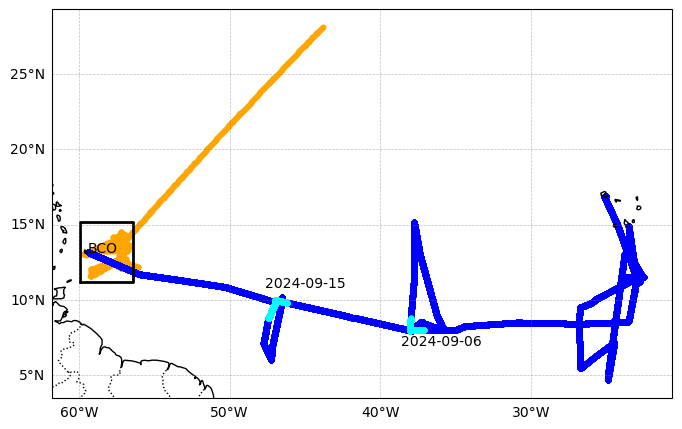

In [7]:
BCO_lon = -59.4288
BCO_lat = 13.1627
vol_lon = [BCO_lon-0.5   , BCO_lon+3] 
vol_lat = [BCO_lat-2   , BCO_lat+2] 



# - presenting area of interest

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

## meteor EU
ax.scatter(allFluxes_eu.lon, allFluxes_eu.lat, c='orange', s=10, transform=ccrs.PlateCarree())
## meteor OR
ax.scatter(meteor_or.lon, meteor_or.lat, c='blue', s=10, transform=ccrs.PlateCarree())


# Add base features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
# ax.set_extent([vol_lon[0] - 1.5, vol_lon[1] + 1.5, vol_lat[0] - 1.5, vol_lat[1] + 1.5], crs=ccrs.PlateCarree())

# Draw the rectangle (as a closed polygon)
lons = [vol_lon[0], vol_lon[1], vol_lon[1], vol_lon[0], vol_lon[0]]
lats = [vol_lat[0], vol_lat[0], vol_lat[1], vol_lat[1], vol_lat[0]]
ax.plot(lons, lats, color='k', linewidth=2, transform=ccrs.PlateCarree())


ax.text(BCO_lon, BCO_lat, "BCO")


### where was Meteor on the 6th of Sept.? i.e. when radiosondes at BCO started and HALO moved to the West
meteor_6thSept = meteor_or.sel(time=slice("2024-09-06T00:00", "2024-09-06T22:59"))
ax.scatter(meteor_6thSept.lon, meteor_6thSept.lat, c='cyan', s=10, transform=ccrs.PlateCarree())
ax.text(meteor_6thSept.lon[0]-1.5, meteor_6thSept.lat[0]-1., "2024-09-06")

meteor_15thSept = meteor_or.sel(time=slice("2024-09-15T00:00", "2024-09-15T22:59"))
ax.scatter(meteor_15thSept.lon, meteor_15thSept.lat, c='cyan', s=10, transform=ccrs.PlateCarree())
ax.text(meteor_15thSept.lon[0]-1.5, meteor_15thSept.lat[0]+1., "2024-09-15")








gl = ax.gridlines(draw_labels=True, 
                  linewidth=0.5, color='gray', alpha=0.5, linestyle='--')

# Turn on labels on bottom and left only
gl.top_labels = False
gl.right_labels = False

# Optionally format ticks (degrees + symbols)
gl.xformatter = cticker.LongitudeFormatter()
gl.yformatter = cticker.LatitudeFormatter()



# - set control volume edges





##### add circle coordinates to the map

In [121]:
beach4 = xr.open_dataset("ipfs://bafybeibgeeqs5uhmbqy4hz4v3pihrfisiklcetisxkf63d2r473szaprwi", engine="zarr")
lon_condition = (beach4.circle_lon < -40) & (beach4.launch_lon < -40)
beach4 = beach4.rename({'altitude': 'alt'}).sel(alt=slice(0,7000)).where(lon_condition, drop=True)

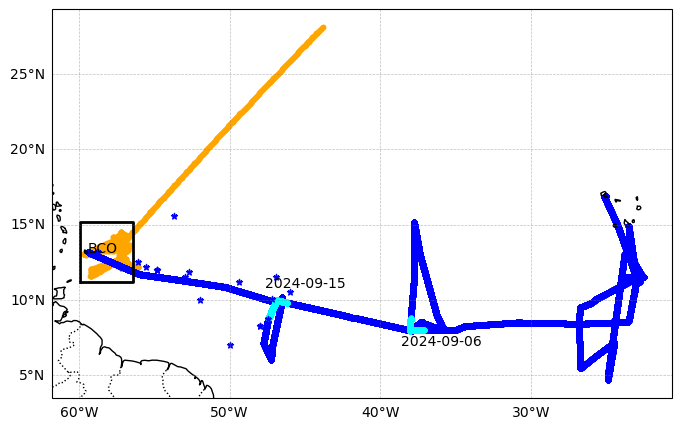

In [131]:
BCO_lon = -59.4288
BCO_lat = 13.1627
vol_lon = [BCO_lon-0.5   , BCO_lon+3] 
vol_lat = [BCO_lat-2   , BCO_lat+2] 



# - presenting area of interest

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

## meteor EU
ax.scatter(allFluxes_eu.lon, allFluxes_eu.lat, c='orange', s=10, transform=ccrs.PlateCarree())
## meteor OR
ax.scatter(meteor_or.lon, meteor_or.lat, c='blue', s=10, transform=ccrs.PlateCarree())


# Add base features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
# ax.set_extent([vol_lon[0] - 1.5, vol_lon[1] + 1.5, vol_lat[0] - 1.5, vol_lat[1] + 1.5], crs=ccrs.PlateCarree())

# Draw the rectangle (as a closed polygon)
lons = [vol_lon[0], vol_lon[1], vol_lon[1], vol_lon[0], vol_lon[0]]
lats = [vol_lat[0], vol_lat[0], vol_lat[1], vol_lat[1], vol_lat[0]]
ax.plot(lons, lats, color='k', linewidth=2, transform=ccrs.PlateCarree())


ax.text(BCO_lon, BCO_lat, "BCO")


### where was Meteor on the 6th of Sept.? i.e. when radiosondes at BCO started and HALO moved to the West
meteor_6thSept = meteor_or.sel(time=slice("2024-09-06T00:00", "2024-09-06T22:59"))
ax.scatter(meteor_6thSept.lon, meteor_6thSept.lat, c='cyan', s=10, transform=ccrs.PlateCarree())
ax.text(meteor_6thSept.lon[0]-1.5, meteor_6thSept.lat[0]-1., "2024-09-06")

meteor_15thSept = meteor_or.sel(time=slice("2024-09-15T00:00", "2024-09-15T22:59"))
ax.scatter(meteor_15thSept.lon, meteor_15thSept.lat, c='cyan', s=10, transform=ccrs.PlateCarree())
ax.text(meteor_15thSept.lon[0]-1.5, meteor_15thSept.lat[0]+1., "2024-09-15")



## ORCESTRA circle locations
day = beach4.circle_time.dt.floor("D")
mask = (day >= np.datetime64("2024-09-15")) & (day <= np.datetime64("2024-09-24"))
b = beach4.where(mask, drop=True)
ax.scatter(b.circle_lon, b.circle_lat, c='blue', s=20, marker="*", transform=ccrs.PlateCarree())




gl = ax.gridlines(draw_labels=True, 
                  linewidth=0.5, color='gray', alpha=0.5, linestyle='--')

# Turn on labels on bottom and left only
gl.top_labels = False
gl.right_labels = False

# Optionally format ticks (degrees + symbols)
gl.xformatter = cticker.LongitudeFormatter()
gl.yformatter = cticker.LatitudeFormatter()



# - set control volume edges





## reconstruct ORCESTRA sfc fluxes with COARE

In [114]:

within_volume_eu = (
    (allFluxes_eu.lon >= vol_lon[0]) & (allFluxes_eu.lon <= vol_lon[1]) &
    (allFluxes_eu.lat >= vol_lat[0]) & (allFluxes_eu.lat <= vol_lat[1])
)
# Use .isel() with the boolean mask converted to indices
indices = within_volume_eu.values.nonzero()[0]  # adjust dim index if needed
allFluxes_eu_sub = allFluxes_eu.isel(time=indices)    # replace 'time' with your main dim


within_volume_or = (
    (meteor_or.lon >= vol_lon[0]) & (meteor_or.lon <= vol_lon[1]) &
    (meteor_or.lat >= vol_lat[0]) & (meteor_or.lat <= vol_lat[1])
)
# Use .isel() with the boolean mask converted to indices
indices = within_volume_or.values.nonzero()[0]  # adjust dim index if needed
meteor_or_sub = meteor_or.isel(time=indices)    # replace 'time' with your main dim

In [115]:
allFluxes_eu_sub

<xarray.Dataset> Size: 333kB
Dimensions:                      (time: 1810, nbnds: 2)
Coordinates:
  * time                         (time) datetime64[ns] 14kB 2020-01-15 ... 20...
Dimensions without coordinates: nbnds
Data variables: (12/41)
    lat                          (time) float32 7kB 13.07 13.07 ... 16.1 16.16
    lon                          (time) float32 7kB -59.65 -59.65 ... -54.96
    time_bnds                    (time, nbnds) datetime64[ns] 29kB ...
    SHF_EC_mast                  (time) float32 7kB ...
    SHF_bulk_mast                (time) float32 7kB ...
    LHF_EC_mast                  (time) float32 7kB ...
    ...                           ...
    mask_despiking_T_mast        (time) float32 7kB ...
    mask_despiking_Z_mast        (time) float32 7kB ...
    mask_data_availability_mast  (time) float32 7kB ...
    mask_vsea_bulk_mast          (time) float32 7kB ...
    mask_vsea_bulk_bow           (time) float32 7kB ...
    mask_LHF_EC_bow_transit      (time) float32 7kB ...
Attributes:
    title:           Eddy-Covariance and bulk turbulent surface fluxes averag...
    history:         Created 21-09-21
    institution:     Meteorological Institute, Universitaet Hamburg
    contact_person:  Imke Schirmacher (imke.schirmacher@uni-koeln.de), Ingo L...
    source:          Ultra-Sonic Anemometer/Thermometer METEK uSonic-3 Scient...
    comments:        The surface fluxes are processed and flagged (nan) by th...
    authors:         Schirmacher, Imke; Lange, Ingo

In [116]:
time_window = meteor_or_sub.time # slice( '2024-08-14', '2024-09-23' )

u = meteor_or.wspd_rel.sel(time=time_window)
t = meteor_or.t_air_port.sel(time=time_window)
rh = meteor_or.rh_port.sel(time=time_window)
ts = meteor_or.sst_port.sel(time=time_window)
P = meteor_or.p_air.sel(time=time_window)
Rs = meteor_or.swr.sel(time=time_window)
Rl = meteor_or.lwr.sel(time=time_window)

output_meteor_or = coare35vn.coare35vn(u=u.values.flatten(),
                             t=t.values.flatten()-273.15,
                             rh=rh.values.flatten(),
                             ts=ts.values.flatten()-273.15,
                             P=P.values.flatten()/100.,
                             Rs=Rs.values.flatten(),
                             Rl=Rl.values.flatten(), 
                             zu=28, zt=28, zq=28, lat=13, zi=500, rain=None, cp=None, sigH=None, jcool=1)


lhf_meteor_or_sub = xr.DataArray(
        output_meteor_or[:,1],
        dims=("time"),
        coords={
            "time": meteor_or.sel(time=time_window).time.values,
            "lat":  ("time",meteor_or.sel(time=time_window).lat.values),
            "lon":  ("time",meteor_or.sel(time=time_window).lon.values),
        },
        attrs={
        "units": "W/m2",
        "description": "bulk reconstruction of Meteor OR LHF"
        },

        name="LHF"
                )

shf_meteor_or_sub = xr.DataArray(
        output_meteor_or[:,0],
        dims=("time"),
        coords={
            "time": meteor_or.sel(time=time_window).time.values,
            "lat":  ("time",meteor_or.sel(time=time_window).lat.values),
            "lon":  ("time",meteor_or.sel(time=time_window).lon.values),
        },
        attrs={
        "units": "W/m2",
        "description": "bulk reconstruction of Meteor OR SHF"
        },

        name="SHF"
                )

/Users/alessandrostorer/Desktop/PhD/1st_yy/work/codes/COARE3.5/meteo.py:157: RuntimeWarning: invalid value encountered in power
  psi = -((1 + 0.6667*zet)**1.5 + 0.6667*(zet - 14.28)*exp(-dzet) + 8.525)


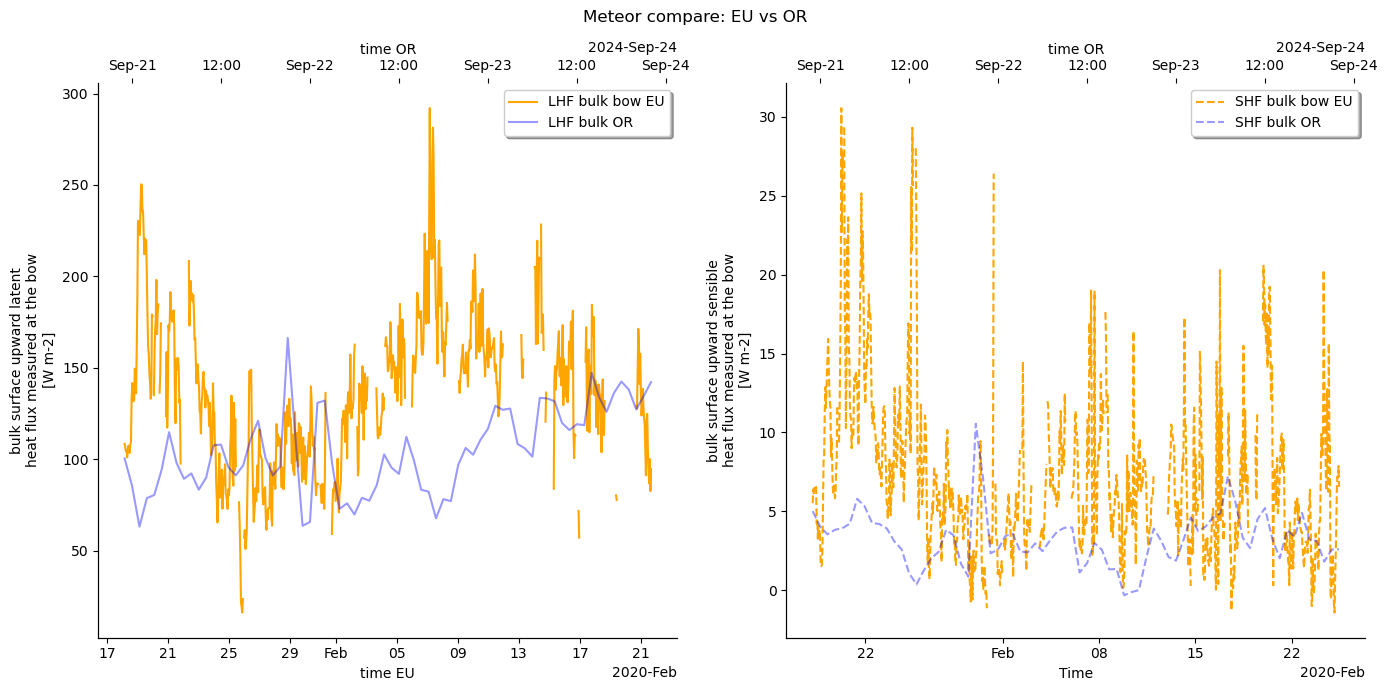

In [117]:
fig, ax = plt.subplots(1,2, figsize=(14, 7))
fig.suptitle("Meteor compare: EU vs OR")

## lhf eurec4a
allFluxes_eu_sub.LHF_bulk_bow.resample(time="1h").mean().plot.line(ax=ax[0], x="time", label="LHF bulk bow EU", color="orange")
ax[0].set_xlabel("time EU")

## lhf orcestra
ax1 = ax[0].twiny()
lhf_meteor_or_sub.resample(time="1h").mean().plot.line(ax=ax1, x="time", label="LHF bulk OR", color="blue", alpha=0.4)
ax1.set_xlabel("time OR")

# Collect all handles and labels from both axes
lines1, labels1 = ax[0].get_legend_handles_labels()
lines2, labels2 = ax1.get_legend_handles_labels()

# Combine them
all_lines = lines1 + lines2
all_labels = labels1 + labels2

# Create a single legend on ax[0]
ax[0].legend(all_lines, all_labels, loc='upper right', frameon=True, fancybox=True, shadow=True)






## shf eurec4a
allFluxes_eu.SHF_bulk_bow.resample(time="1h").mean().plot.line(ax=ax[1], x="time", label="SHF bulk bow EU", color="orange", linestyle="dashed")

## shf orcestra
ax2 = ax[1].twiny()
shf_meteor_or_sub.resample(time="1h").mean().plot.line(ax=ax2, x="time", label="SHF bulk OR", color="blue", alpha=0.4, linestyle="dashed")
ax2.set_xlabel("time OR")

# Collect all handles and labels from both axes
lines1, labels1 = ax[1].get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

# Combine them
all_lines = lines1 + lines2
all_labels = labels1 + labels2

# Create a single legend on ax[0]
ax[1].legend(all_lines, all_labels, loc='upper right', frameon=True, fancybox=True, shadow=True)



for x in [ax[0], ax[1], ax1, ax2]:
    for spine in ['top', 'right']:
            x.spines[spine].set_visible(False)
    

plt.tight_layout()

NameError: name 'lhf_meteor_or_sub' is not defined

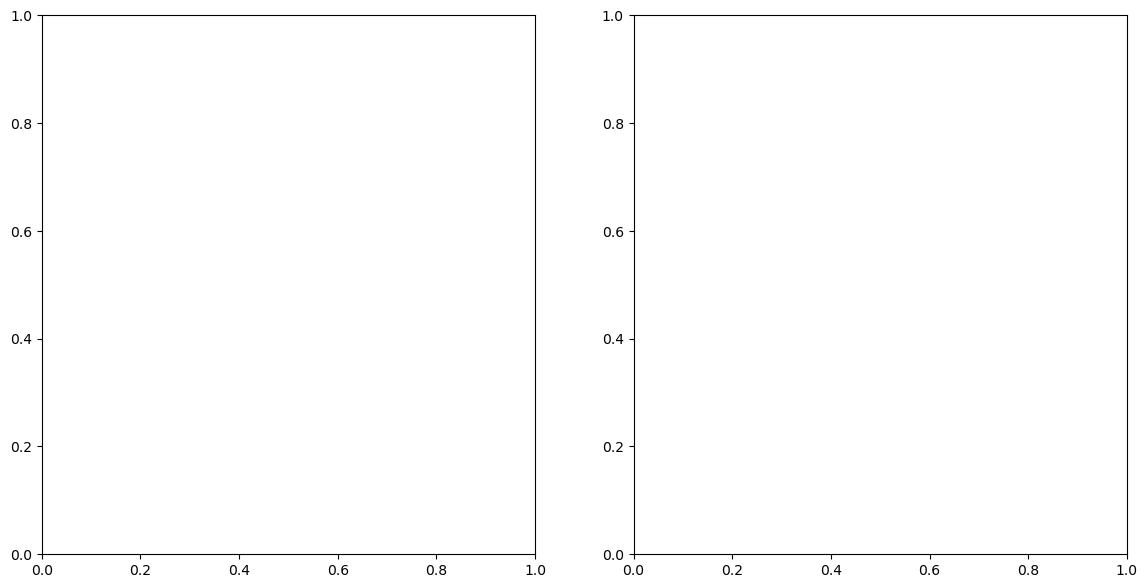

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7))

series = [
    # (axis, data, color, label)
    (ax[0], allFluxes_eu_sub.LHF_bulk_bow, "orange", "bulk"),
    (ax[0], lhf_meteor_or_sub,             "blue",   "meteor"),
    (ax[1], allFluxes_eu.SHF_bulk_bow,     "orange", "bulk"),
    (ax[1], shf_meteor_or_sub,             "blue",   "meteor"),
]

for a, da, c, lab in series:
    da.plot.hist(ax=a, bins=30, histtype="step", color=c, density=True, label=lab)
    mu = float(da.mean(skipna=True))
    a.axvline(mu, color=c, ls="--", lw=1.5, label=f"{lab} mean = {mu:.1f}")

ax[0].set_xlabel("LHF (W m$^{-2}$)")
ax[1].set_xlabel("SHF (W m$^{-2}$)")
for a in ax:
    a.legend()

for axx in ax:
    for spine in ['top', 'right']:
        axx.spines[spine].set_visible(False)

    for spine in ['left', 'bottom']:
        axx.spines[spine].set_position(("outward", 10))


plt.show()

#### plotting data I use in computations of mass fluxes

In [2]:
###### bulk fluxes from one week of ship measurements
flux_path_local = "/Users/alessandrostorer/Desktop/PhD/1st_yy/work/datasets/actual_fluxes/Bulk_fluxes_from_Meteor.nc"
flux_path = "/work/mh1498/m301248/TCO_data/fluxes_data/Bulk_fluxes_from_Meteor.nc"
ds_bulkFluxes = xr.open_dataset(flux_path_local)
lhf_recShip_eu = ds_bulkFluxes.LHF_eu.mean(dim="time_eu")
lhf_recShip_or = ds_bulkFluxes.LHF_or.mean(dim="time_or")
shf_recShip_eu = ds_bulkFluxes.SHF_eu.mean(dim="time_eu")
shf_recShip_or = ds_bulkFluxes.SHF_or.mean(dim="time_or")

In [11]:
ds_bulkFluxes.LHF_or

<xarray.DataArray 'LHF_or' (time_or: 7140)> Size: 57kB
array([ 85.348339,  82.343618,  76.598653, ..., 130.77639 , 121.041759,
       107.21131 ], shape=(7140,))
Coordinates:
  * time_or  (time_or) datetime64[ns] 57kB 2024-09-19 ... 2024-09-23T22:59:00
    lat_or   (time_or) float64 57kB ...
    lon_or   (time_or) float64 57kB ...
Attributes:
    units:        W/m2
    description:  bulk reconstruction of Meteor OR LHF

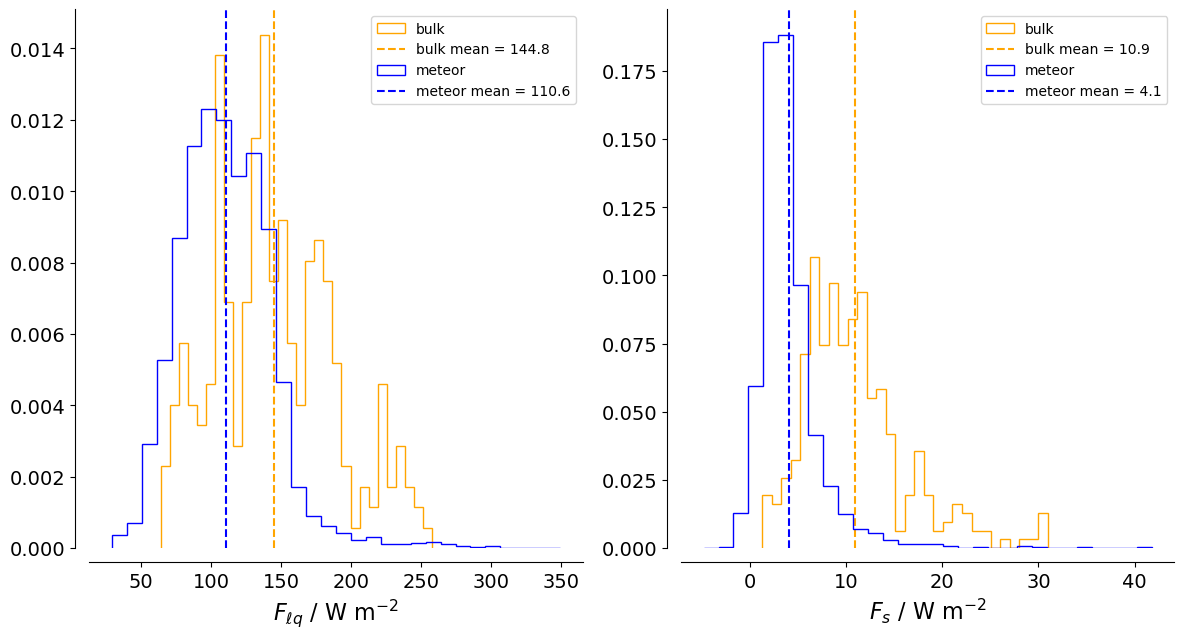

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7))

series = [
    # (axis, data, color, label)
    (ax[0], ds_bulkFluxes.LHF_eu, "orange", "bulk"),
    (ax[0], ds_bulkFluxes.LHF_or,             "blue",   "meteor"),
    (ax[1], ds_bulkFluxes.SHF_eu,     "orange", "bulk"),
    (ax[1], ds_bulkFluxes.SHF_or,             "blue",   "meteor"),
]

for a, da, c, lab in series:
    da.plot.hist(ax=a, bins=30, histtype="step", color=c, density=True, label=lab)
    mu = float(da.mean(skipna=True))
    a.axvline(mu, color=c, ls="--", lw=1.5, label=f"{lab} mean = {mu:.1f}")

ax[0].set_xlabel(r"$F_{\ell q}$ / W m$^{-2}$", fontsize=16)
ax[1].set_xlabel(r"$F_s$ / W m$^{-2}$", fontsize=16)
for a in ax:
    a.legend()

for axx in ax:
    axx.tick_params(axis='both', which='major', labelsize=14)
    for spine in ['top', 'right']:
        axx.spines[spine].set_visible(False)

    for spine in ['left', 'bottom']:
        axx.spines[spine].set_position(("outward", 10))


plt.show()

In [9]:
allFluxes_eu_sub = allFluxes_eu.sel(time=slice(ds_bulkFluxes.LHF_eu.time_eu.values[0], ds_bulkFluxes.LHF_eu.time_eu.values[-1]))
meteor_or_sub = meteor_or.sel(time=slice(ds_bulkFluxes.LHF_or.time_or.values[0], ds_bulkFluxes.LHF_or.time_or.values[-1]))

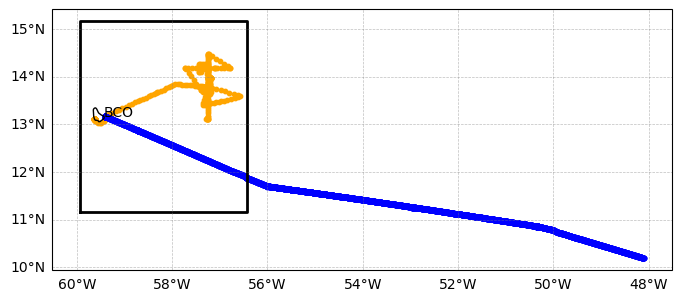

In [10]:
BCO_lon = -59.4288
BCO_lat = 13.1627
vol_lon = [BCO_lon-0.5   , BCO_lon+3] 
vol_lat = [BCO_lat-2   , BCO_lat+2] 



# - presenting area of interest

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

## meteor EU
ax.scatter(allFluxes_eu_sub.lon, allFluxes_eu_sub.lat, c='orange', s=10, transform=ccrs.PlateCarree())
## meteor OR
ax.scatter(meteor_or_sub.lon, meteor_or_sub.lat, c='blue', s=10, transform=ccrs.PlateCarree())


# Add base features
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
# ax.set_extent([vol_lon[0] - 1.5, vol_lon[1] + 1.5, vol_lat[0] - 1.5, vol_lat[1] + 1.5], crs=ccrs.PlateCarree())

# Draw the rectangle (as a closed polygon)
lons = [vol_lon[0], vol_lon[1], vol_lon[1], vol_lon[0], vol_lon[0]]
lats = [vol_lat[0], vol_lat[0], vol_lat[1], vol_lat[1], vol_lat[0]]
ax.plot(lons, lats, color='k', linewidth=2, transform=ccrs.PlateCarree())


ax.text(BCO_lon, BCO_lat, "BCO")


# ### where was Meteor on the 6th of Sept.? i.e. when radiosondes at BCO started and HALO moved to the West
# meteor_6thSept = meteor_or.sel(time=slice("2024-09-06T00:00", "2024-09-06T22:59"))
# ax.scatter(meteor_6thSept.lon, meteor_6thSept.lat, c='cyan', s=10, transform=ccrs.PlateCarree())
# ax.text(meteor_6thSept.lon[0]-1.5, meteor_6thSept.lat[0]-1., "2024-09-06")

# meteor_15thSept = meteor_or.sel(time=slice("2024-09-15T00:00", "2024-09-15T22:59"))
# ax.scatter(meteor_15thSept.lon, meteor_15thSept.lat, c='cyan', s=10, transform=ccrs.PlateCarree())
# ax.text(meteor_15thSept.lon[0]-1.5, meteor_15thSept.lat[0]+1., "2024-09-15")








gl = ax.gridlines(draw_labels=True, 
                  linewidth=0.5, color='gray', alpha=0.5, linestyle='--')

# Turn on labels on bottom and left only
gl.top_labels = False
gl.right_labels = False

# Optionally format ticks (degrees + symbols)
gl.xformatter = cticker.LongitudeFormatter()
gl.yformatter = cticker.LatitudeFormatter()



# - set control volume edges





#### compare bulk estimates with EC measurements (EUREC4A only)

In [70]:
from scipy.stats import linregress

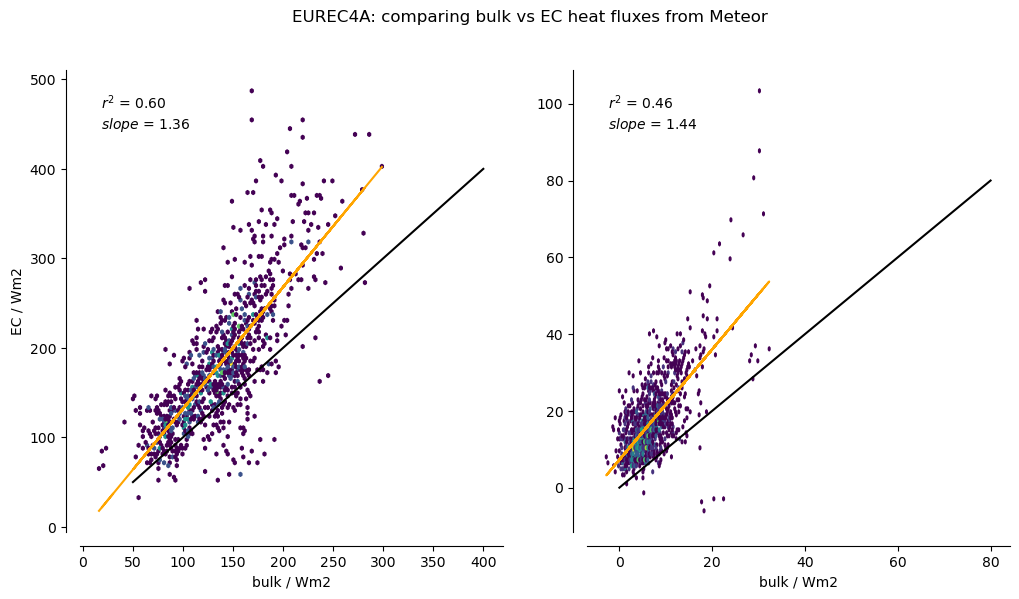

In [81]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle("EUREC4A: comparing bulk vs EC heat fluxes from Meteor")
corr = []
regress = []

x, y = allFluxes_eu_sub.LHF_bulk_bow, allFluxes_eu_sub.LHF_EC_bow
xv, yv, = x.values.ravel(), y.values.ravel()
m = np.isfinite(xv) & np.isfinite(yv)
res = linregress(xv[m], yv[m])
regress.append(res)

ax[0].hexbin(x,y, gridsize=(100,70), mincnt=1)
ax[0].plot([50, 400], [50, 400], "k")
ax[0].plot(x, res.slope * x + res.intercept, "orange")
ax[0].set_xlabel("bulk / Wm2")
ax[0].set_ylabel("EC / Wm2")
corr.append(float(xr.corr(x, y)))



x, y = allFluxes_eu_sub.SHF_bulk_bow, allFluxes_eu_sub.SHF_EC_bow
xv, yv, = x.values.ravel(), y.values.ravel()
m = np.isfinite(xv) & np.isfinite(yv)
res = linregress(xv[m], yv[m])
regress.append(res)
ax[1].hexbin(x, y, gridsize=(100,70), mincnt=1)
ax[1].plot([0, 80], [0, 80], "k")
ax[1].plot(x, res.slope * x + res.intercept, "orange")
ax[1].set_xlabel("bulk / Wm2")
corr.append(float(xr.corr(x, y)))


for axx, r, regr in zip(ax, corr, regress):
    axx.text(0.05, 0.95, fr"$r^2$ = {r**2:.2f}", transform=axx.transAxes,
           ha="left", va="top",
           bbox=dict(boxstyle="round", fc="white", ec="none", alpha=0.8))

    axx.text(0.05, 0.9, fr"$slope$ = {regr.slope:.2f}", transform=axx.transAxes,
           ha="left", va="top",
           bbox=dict(boxstyle="round", fc="white", ec="none", alpha=0.8))
    
    for spine in ['top', 'right']:
        axx.spines[spine].set_visible(False)

    for spine in ['left', 'bottom']:
        axx.spines[spine].set_position(("outward", 10))